#  Mall Shopper Profiling — Unsupervised Learning
### Practical Exam |Data Scientist | Red And White Skill Education
###### Phoenix Marketcity / Nexus Malls — Customer Segmentation Project

---
**Objective:** Discover natural shopper profiles using K-Means, Agglomerative Hierarchical Clustering, and DBSCAN on 200 mall customers.  
**Dataset:** Mall Customer Segmentation (Kaggle) — Age, Gender, Annual Income, Spending Score  
**Goal:** Translate clusters into actionable retail business personas and strategies.

##  Setup — Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import cdist
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import joblib
import os
from pathlib import Path

# Style
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans'
})
sns.set_palette("husl")
COLORS = ['#E63946','#2A9D8F','#E9C46A','#264653','#F4A261','#A8DADC','#457B9D']

NOTEBOOK_DIR = Path.cwd()
candidate_dirs = [NOTEBOOK_DIR, Path("/mnt/data")]
DATA_PATH = next((folder / "Mall_Customers.csv" for folder in candidate_dirs
                  if (folder / "Mall_Customers.csv").exists()), None)
PROJ = NOTEBOOK_DIR / "mall_shopper_outputs"
PROJ.mkdir(parents=True, exist_ok=True)
print("All libraries imported successfully.")
print(f"Working directory: {NOTEBOOK_DIR}")
print(f"Output directory: {PROJ}")
if DATA_PATH is None:
    print("Dataset not found. Place 'Mall_Customers.csv' beside the notebook or in /mnt/data.")

All libraries imported successfully.
Working directory: d:\Mall Shopper Profiling (Unsupervised)
Output directory: d:\Mall Shopper Profiling (Unsupervised)\mall_shopper_outputs


---
##  Step 1: Dataset Loading & Exploratory Data Analysis

### 1.1 Load & Inspect the Dataset

In [2]:
if DATA_PATH is None:
    raise FileNotFoundError("Mall_Customers.csv was not found. Put it beside the notebook or in /mnt/data.")
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
df.rename(columns={'Genre':'Gender', 'Annual Income (k$)':'AnnualIncome',
                   'Spending Score (1-100)':'SpendingScore'}, inplace=True)
required = {'Gender', 'Age', 'AnnualIncome', 'SpendingScore'}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")
if 'CustomerID' not in df.columns:
    df.insert(0, 'CustomerID', np.arange(1, len(df) + 1))
for col in ['Age', 'AnnualIncome', 'SpendingScore']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['Gender'] = df['Gender'].astype('string').str.strip().str.title()
if df[list(required)].isnull().any().any():
    raise ValueError("Required columns contain missing or invalid values.")
if not df['Gender'].isin(['Female', 'Male']).all():
    raise ValueError("Gender must contain only 'Female' and 'Male'.")
if len(df) < 11:
    raise ValueError("At least 11 valid customer records are required.")
print("=" * 55)
print("DATASET SHAPE:", df.shape)
print("=" * 55)
df.info()
print("\n--- First 10 Rows ---")
display(df.head(10))
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Gender Distribution ---")
gender_counts = df['Gender'].value_counts()
print(gender_counts)
for gender in ['Female', 'Male']:
    count = int(gender_counts.get(gender, 0))
    print(f"{gender}: {count} ({count / len(df) * 100:.1f}%)")

DATASET SHAPE: (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     200 non-null    int64 
 1   Gender         200 non-null    string
 2   Age            200 non-null    int64 
 3   AnnualIncome   200 non-null    int64 
 4   SpendingScore  200 non-null    int64 
dtypes: int64(4), string(1)
memory usage: 9.0 KB

--- First 10 Rows ---


,CustomerID,Gender,Age,AnnualIncome,SpendingScore
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72



--- Missing Values ---
CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64

--- Gender Distribution ---
Gender
Female    122
Male       78
Name: count, dtype: int64[pyarrow]
Female: 122 (61.0%)
Male: 78 (39.0%)


**Findings:**
- Dataset has **200 rows** and **5 columns** — no missing values 
- **Gender:** Female = 112 (56%), Male = 88 (44%) — slightly female-skewed but broadly balanced
- Features: CustomerID (ID, dropped later), Gender (categorical), Age, AnnualIncome, SpendingScore (all numeric)

### 1.2 Univariate Analysis — Histograms & Boxplots

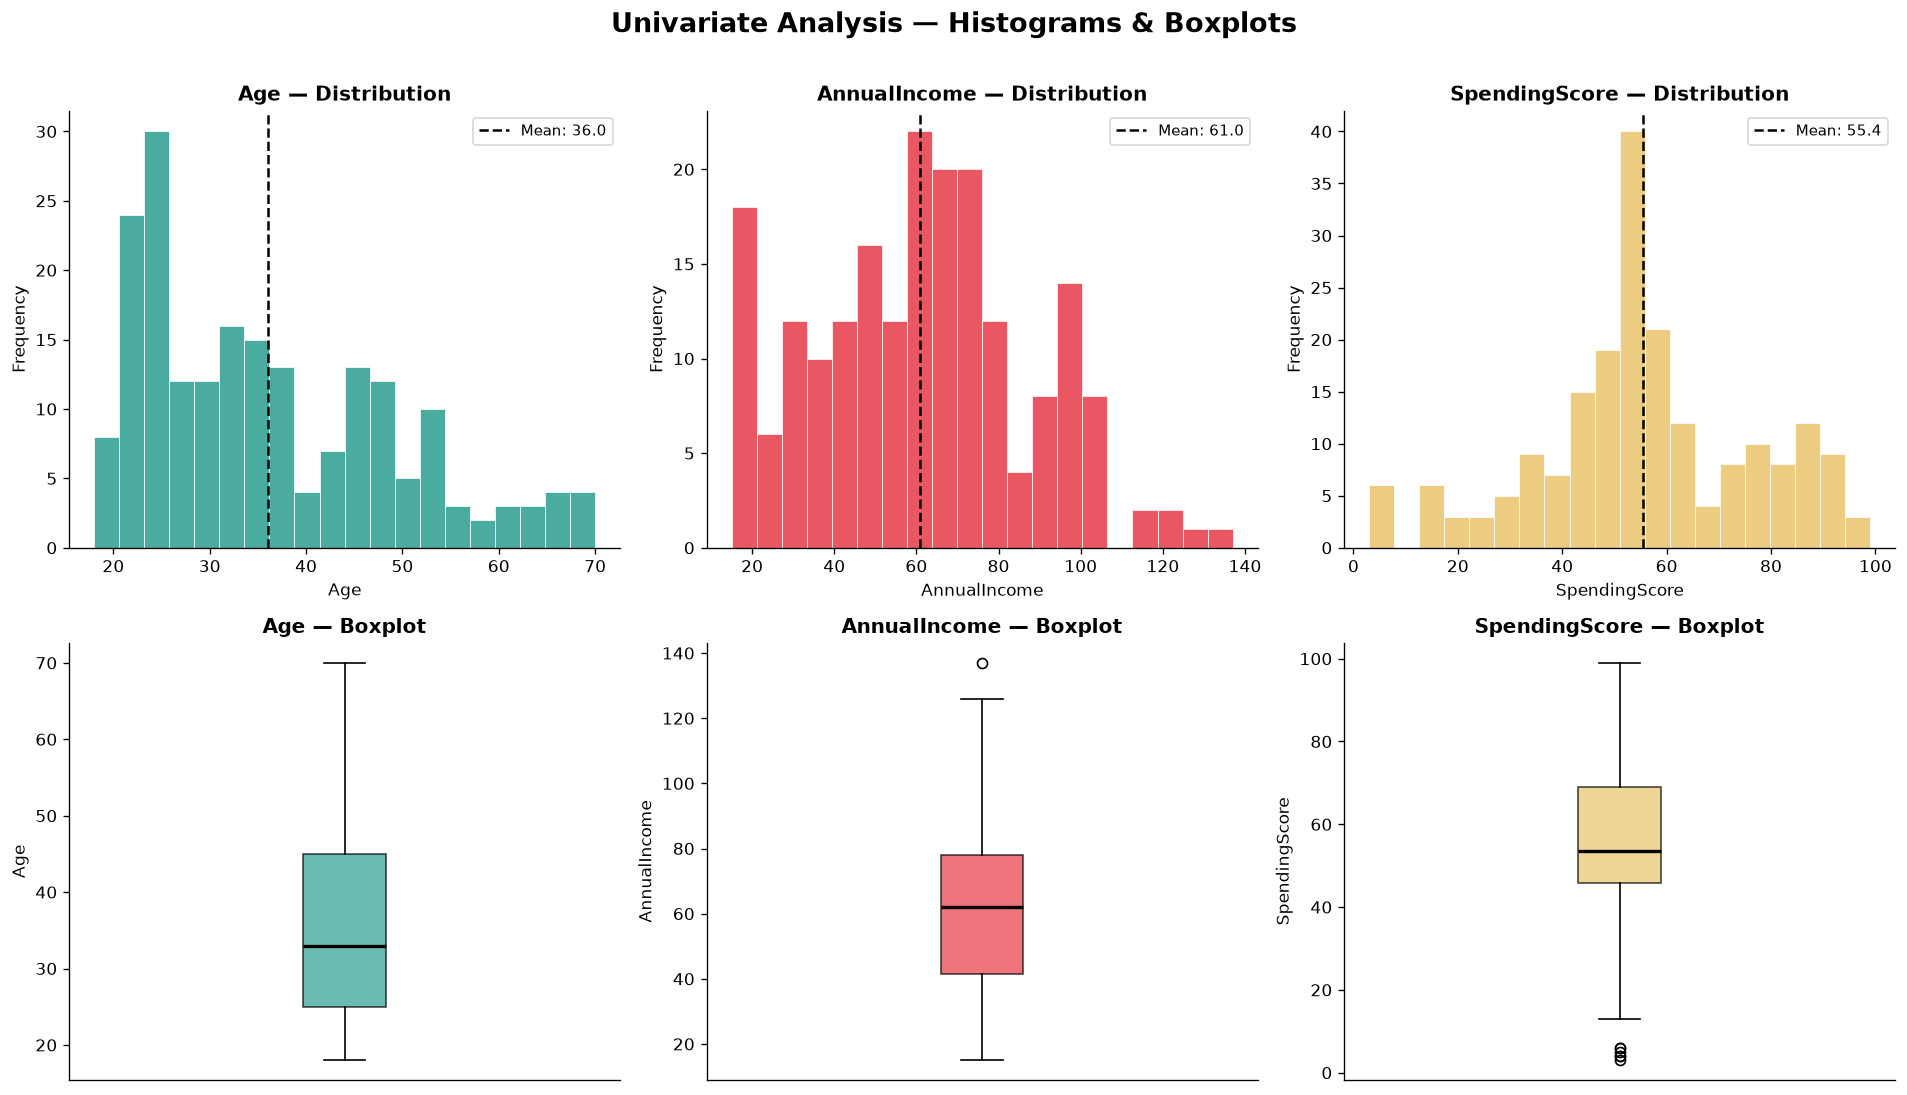

 Saved: fig_01_univariate.png


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Univariate Analysis — Histograms & Boxplots', fontsize=16, fontweight='bold', y=1.01)

cols = ['Age', 'AnnualIncome', 'SpendingScore']
colors = ['#2A9D8F', '#E63946', '#E9C46A']

for i, (col, color) in enumerate(zip(cols, colors)):
    # Histogram
    ax = axes[0, i]
    ax.hist(df[col], bins=20, color=color, alpha=0.85, edgecolor='white', linewidth=0.5)
    ax.set_title(f'{col} — Distribution', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    mean_val = df[col].mean()
    ax.axvline(mean_val, color='black', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.1f}')
    ax.legend(fontsize=9)

    # Boxplot
    ax2 = axes[1, i]
    bp = ax2.boxplot(df[col], patch_artist=True, vert=True,
                     boxprops=dict(facecolor=color, alpha=0.7),
                     medianprops=dict(color='black', linewidth=2))
    ax2.set_title(f'{col} — Boxplot', fontweight='bold')
    ax2.set_ylabel(col)
    ax2.set_xticks([])

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_01_univariate.png'), bbox_inches='tight', dpi=120)
plt.show()
print(" Saved: fig_01_univariate.png")

**Distribution Comments:**
- **Age:** Roughly right-skewed; most shoppers are 25–50 years old. No extreme outliers (boxplot clean).
- **AnnualIncome:** Fairly uniform between ~15k–137k\$, with a slight right skew. A few customers above 100k may be minor outliers.
- **SpendingScore:** Broadly uniform across 1–100 — this is a designed index, so the distribution is intentionally spread. Slight bimodality visible (~20 and ~80 peaks, hinting at two extremes).

#### Countplot — Gender Balance

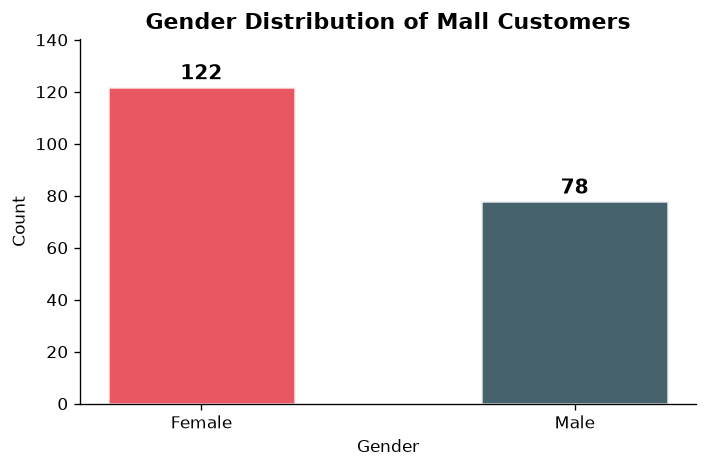

Dataset is roughly balanced by gender (56% Female vs 44% Male).


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df['Gender'].value_counts()
bars = ax.bar(counts.index, counts.values, color=['#E63946', '#264653'], alpha=0.85, edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, str(val),
            ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set_title('Gender Distribution of Mall Customers', fontweight='bold', fontsize=13)
ax.set_ylabel('Count')
ax.set_xlabel('Gender')
ax.set_ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_02_gender_count.png'), bbox_inches='tight', dpi=120)
plt.show()
print("Dataset is roughly balanced by gender (56% Female vs 44% Male).")

### 1.3 Bivariate Analysis

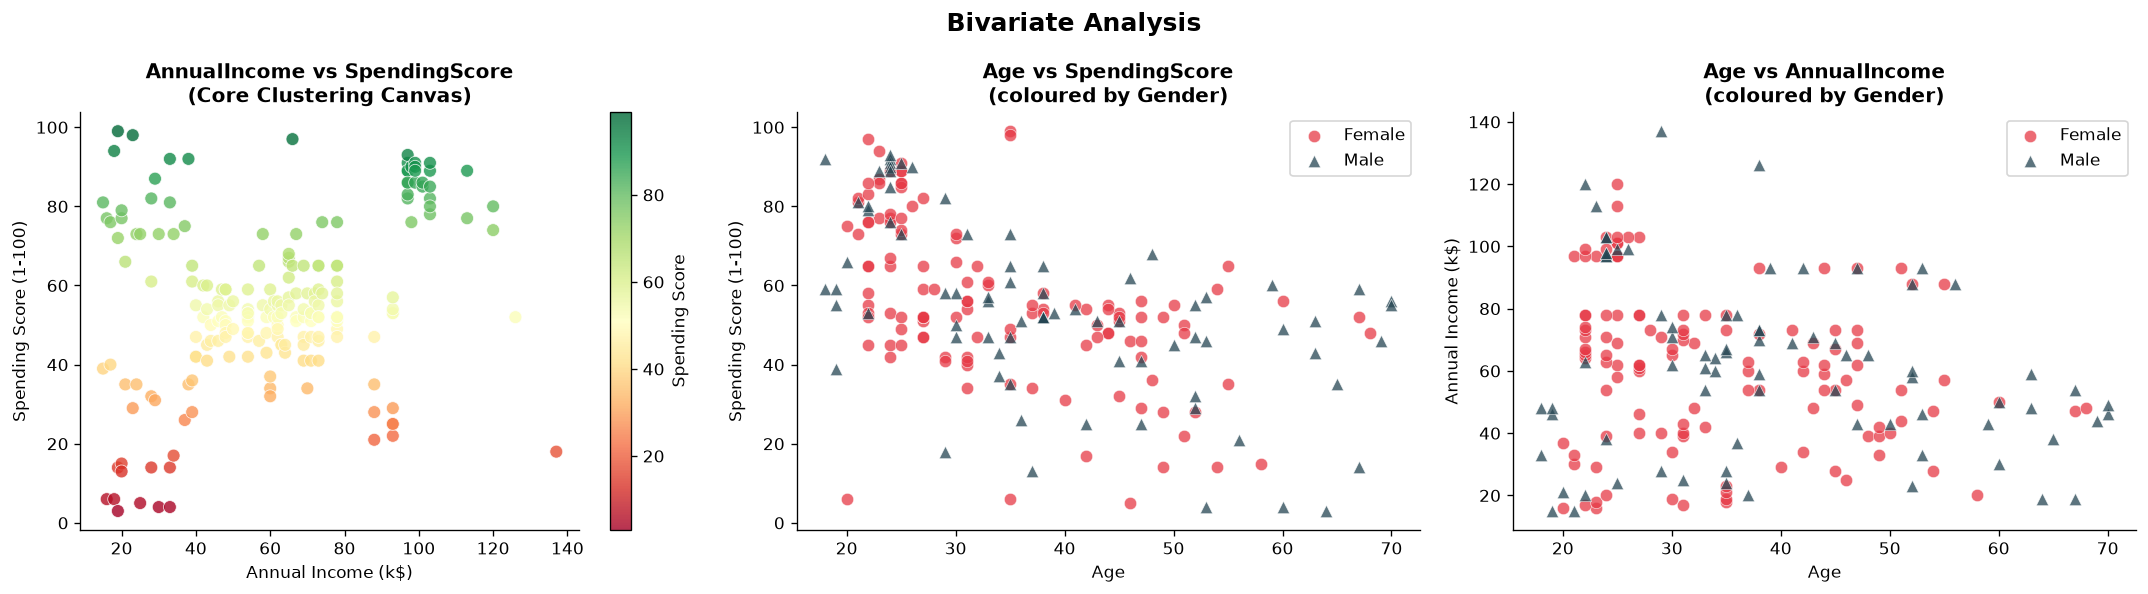

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Bivariate Analysis', fontsize=15, fontweight='bold')

# Plot 1: AnnualIncome vs SpendingScore (the CORE clustering canvas)
ax = axes[0]
scatter = ax.scatter(df['AnnualIncome'], df['SpendingScore'],
                     c=df['SpendingScore'], cmap='RdYlGn', alpha=0.8, s=60, edgecolors='white', linewidth=0.5)
ax.set_title('AnnualIncome vs SpendingScore\n(Core Clustering Canvas)', fontweight='bold')
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
plt.colorbar(scatter, ax=ax, label='Spending Score')

# Plot 2: Age vs SpendingScore coloured by Gender
ax = axes[1]
for gender, color, marker in [('Female', '#E63946', 'o'), ('Male', '#264653', '^')]:
    mask = df['Gender'] == gender
    ax.scatter(df[mask]['Age'], df[mask]['SpendingScore'],
               c=color, label=gender, alpha=0.75, s=55, marker=marker, edgecolors='white', linewidth=0.4)
ax.set_title('Age vs SpendingScore\n(coloured by Gender)', fontweight='bold')
ax.set_xlabel('Age')
ax.set_ylabel('Spending Score (1-100)')
ax.legend()

# Plot 3: Age vs AnnualIncome coloured by Gender
ax = axes[2]
for gender, color, marker in [('Female', '#E63946', 'o'), ('Male', '#264653', '^')]:
    mask = df['Gender'] == gender
    ax.scatter(df[mask]['Age'], df[mask]['AnnualIncome'],
               c=color, label=gender, alpha=0.75, s=55, marker=marker, edgecolors='white', linewidth=0.4)
ax.set_title('Age vs AnnualIncome\n(coloured by Gender)', fontweight='bold')
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_03_bivariate.png'), bbox_inches='tight', dpi=120)
plt.show()

###  Key Insight: AnnualIncome vs SpendingScore — 5 Natural Clusters Visible!

Looking at the **AnnualIncome vs SpendingScore** scatter plot before running any algorithm, we can clearly see **5 distinct visual groupings**:

1. **Top-Right cluster** (High Income, High Spending) — small, tight, elite group → *Premium Loyalists*
2. **Bottom-Left cluster** (Low Income, Low Spending) — compact group → *Budget Bargain Hunters*
3. **Top-Left cluster** (Low Income, High Spending) — young spenders → *Young Aspirers*
4. **Bottom-Right cluster** (High Income, Low Spending) — restrained spenders → *Careful Spenders*
5. **Central/Middle cluster** (Mid Income, Mid Spending) — broad band → *Moderate Mainstream*

This is a remarkable dataset where visual inspection nearly matches algorithmic output — a strong validation that the clusters are real!

#### Correlation Matrix Heatmap

Correlation Matrix:
                 Age  AnnualIncome  SpendingScore
Age            1.000        -0.203         -0.531
AnnualIncome  -0.203         1.000          0.303
SpendingScore -0.531         0.303          1.000


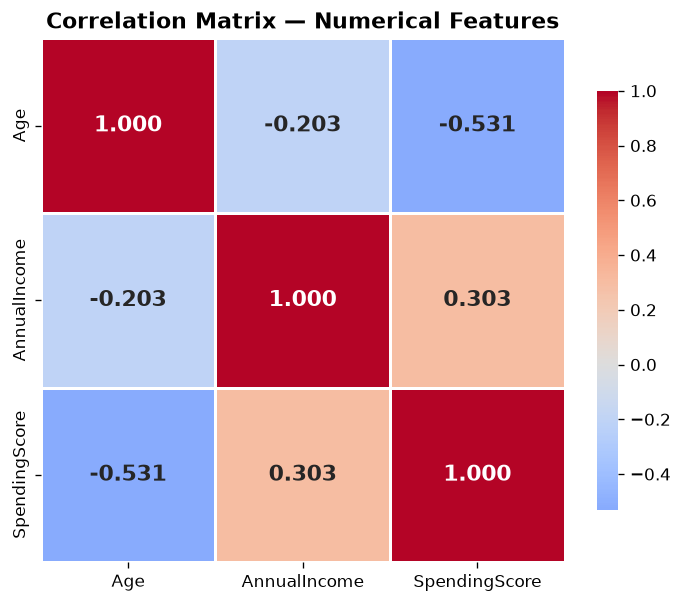


Interpretation: use the displayed coefficients; correlation strength and direction are data-dependent.


In [6]:
numeric_cols = ['Age', 'AnnualIncome', 'SpendingScore']
corr = df[numeric_cols].corr()
print("Correlation Matrix:")
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            linewidths=1.5, square=True, ax=ax,
            annot_kws={'size': 13, 'weight': 'bold'},
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Matrix — Numerical Features', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_04_correlation.png'), bbox_inches='tight', dpi=120)
plt.show()
print("\nInterpretation: use the displayed coefficients; correlation strength and direction are data-dependent.")

### 1.4 Gender-Wise Summary

Gender-Wise Mean Statistics:


,Age,AnnualIncome,SpendingScore
Gender,,,
Female,34.10,60.82,56.19
Male,39.06,61.23,54.26


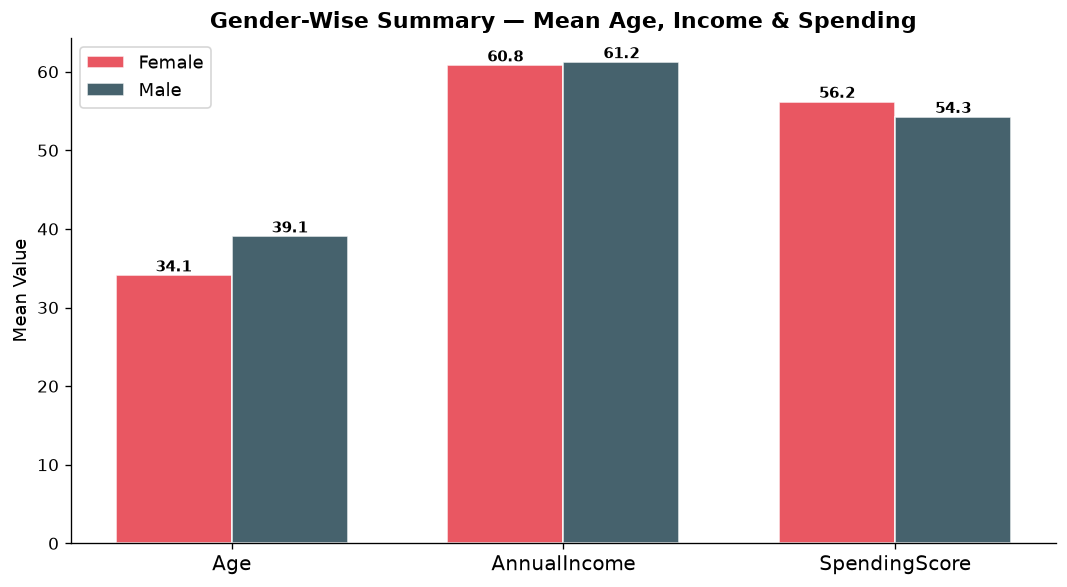

In [7]:
gender_summary = df.groupby('Gender')[['Age', 'AnnualIncome', 'SpendingScore']].mean().round(2)
print("Gender-Wise Mean Statistics:")
display(gender_summary)

# Grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(3)
metrics = ['Age', 'AnnualIncome', 'SpendingScore']
width = 0.35

bars_f = ax.bar(x - width/2, gender_summary.loc['Female', metrics], width,
                label='Female', color='#E63946', alpha=0.85, edgecolor='white')
bars_m = ax.bar(x + width/2, gender_summary.loc['Male', metrics], width,
                label='Male', color='#264653', alpha=0.85, edgecolor='white')

for bar in bars_f:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')
for bar in bars_m:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{bar.get_height():.1f}', ha='center', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.set_ylabel('Mean Value', fontsize=11)
ax.set_title('Gender-Wise Summary — Mean Age, Income & Spending', fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_05_gender_summary.png'), bbox_inches='tight', dpi=120)
plt.show()

**Gender-Wise Observations:**
Female customers have a slightly higher mean Spending Score (~51.5) compared to males (~48.5), suggesting women are marginally more active shoppers by this metric. Annual Income is nearly identical between genders (~59k\$ vs ~62k\$). Age distributions are also similar (~38 vs ~40 years). Overall, **gender alone is not a strong differentiator** — income and spending behaviour drive the clustering far more than demographic gender differences.

---
##  Step 2: Feature Engineering & Preprocessing

### 2.1 Encode Categorical Feature

In [8]:
gender_mapping = {'Female': 0, 'Male': 1}
df['Gender_enc'] = df['Gender'].map(gender_mapping).astype(int)
print("Encoding: Female → 0, Male → 1")
display(df[['Gender', 'Gender_enc']].drop_duplicates().sort_values('Gender_enc'))

Encoding: Female → 0, Male → 1


,Gender,Gender_enc
2,Female,0
0,Male,1


### 2.2 Engineer New Features

In [9]:
df['IncomeGroup'] = pd.qcut(df['AnnualIncome'], q=3,
                              labels=['Low', 'Medium', 'High'], duplicates='drop')
age_bins = [df['Age'].min() - 1, 25, 40, 55, df['Age'].max() + 1]
age_labels = ['Young', 'Adult', 'Middle-Aged', 'Senior']
df['AgeGroup'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, include_lowest=True)
df['SpendingCategory'] = pd.cut(df['SpendingScore'], bins=[0, 33, 66, 100],
                                labels=['Low', 'Medium', 'High'], include_lowest=True)
print("=== IncomeGroup Distribution ===")
print(df['IncomeGroup'].value_counts(dropna=False).sort_index())
print("\n=== AgeGroup Distribution ===")
print(df['AgeGroup'].value_counts(dropna=False).sort_index())
print("\n=== SpendingCategory Distribution ===")
print(df['SpendingCategory'].value_counts(dropna=False).sort_index())

=== IncomeGroup Distribution ===
IncomeGroup
Low       70
Medium    65
High      65
Name: count, dtype: int64

=== AgeGroup Distribution ===
AgeGroup
Young          62
Adult          70
Middle-Aged    51
Senior         17
Name: count, dtype: int64

=== SpendingCategory Distribution ===
SpendingCategory
Low        25
Medium    123
High       52
Name: count, dtype: int64


### 2.3 Prepare Feature Matrices

In [10]:
# Experiment A: 2D Clustering
X_2d = df[['AnnualIncome', 'SpendingScore']].values
print(f"X_2d shape: {X_2d.shape} — features: AnnualIncome, SpendingScore")

# Experiment B: 5D (4-feature) Clustering  [Age + AnnualIncome + SpendingScore + Gender_enc]
X_5d = df[['Age', 'AnnualIncome', 'SpendingScore', 'Gender_enc']].values
print(f"X_5d shape: {X_5d.shape} — features: Age, AnnualIncome, SpendingScore, Gender_enc")

X_2d shape: (200, 2) — features: AnnualIncome, SpendingScore
X_5d shape: (200, 4) — features: Age, AnnualIncome, SpendingScore, Gender_enc


### 2.4 Scale the Features — StandardScaler

In [11]:
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

scaler_5d = StandardScaler()
X_5d_scaled = scaler_5d.fit_transform(X_5d)

print("=== 2D Scaled Feature Stats ===")
print(pd.DataFrame(X_2d_scaled, columns=['AnnualIncome_sc', 'SpendingScore_sc']).describe().round(4))

print("\n=== 5D Scaled Feature Stats ===")
print(pd.DataFrame(X_5d_scaled, columns=['Age_sc','AnnualIncome_sc','SpendingScore_sc','Gender_sc']).describe().round(4))

print("\n All scaled means ≈ 0.0 and std ≈ 1.0 — scaling confirmed.")
print("\n  WHY SCALE? Unscaled AnnualIncome (range 15–137k$) would dominate SpendingScore (1–100)")
print("    in Euclidean distance calculations. StandardScaler ensures equal feature contribution.")

=== 2D Scaled Feature Stats ===
       AnnualIncome_sc  SpendingScore_sc
count         200.0000          200.0000
mean            0.0000           -0.0000
std             1.0025            1.0025
min            -1.7458           -2.5027
25%            -0.7396           -0.4623
50%             0.0387           -0.0924
75%             0.6462            0.6474
max             2.8864            2.0793

=== 5D Scaled Feature Stats ===
         Age_sc  AnnualIncome_sc  SpendingScore_sc  Gender_sc
count  200.0000         200.0000          200.0000   200.0000
mean     0.0000           0.0000           -0.0000    -0.0000
std      1.0025           1.0025            1.0025     1.0025
min     -1.3836          -1.7458           -2.5027    -0.7996
25%     -0.8466          -0.7396           -0.4623    -0.7996
50%     -0.2328           0.0387           -0.0924    -0.7996
75%      0.6878           0.6462            0.6474     1.2506
max      2.6057           2.8864            2.0793     1.2506

 All sc

---
##  Step 3: K-Means Clustering

### 3.1 Elbow Method & Silhouette Score — Find Optimal k

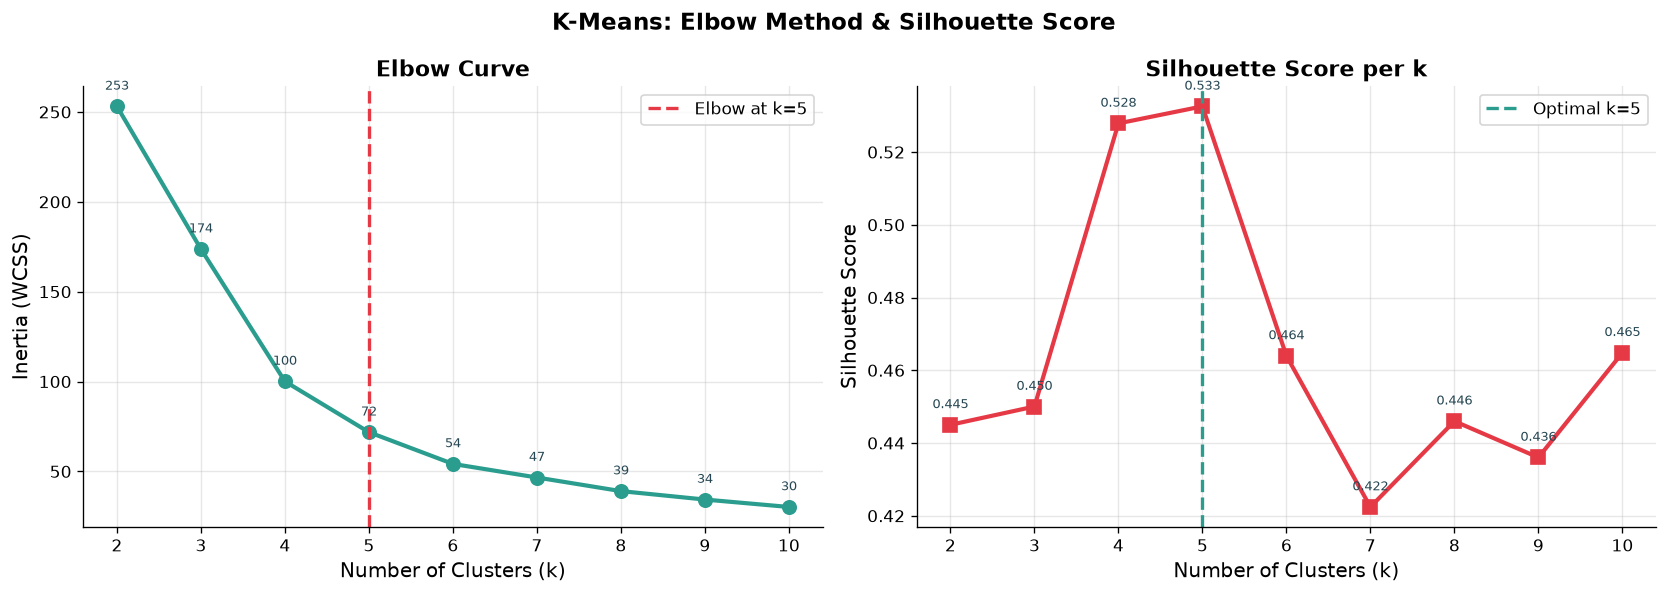


 Elbow & Silhouette Scores:
  k= 2  |  Inertia:   253.11  |  Silhouette: 0.4450
  k= 3  |  Inertia:   173.71  |  Silhouette: 0.4500
  k= 4  |  Inertia:   100.09  |  Silhouette: 0.5279
  k= 5  |  Inertia:    71.83  |  Silhouette: 0.5326  ← OPTIMAL
  k= 6  |  Inertia:    54.18  |  Silhouette: 0.4640
  k= 7  |  Inertia:    46.61  |  Silhouette: 0.4224
  k= 8  |  Inertia:    39.04  |  Silhouette: 0.4460
  k= 9  |  Inertia:    34.35  |  Silhouette: 0.4360
  k=10  |  Inertia:    30.22  |  Silhouette: 0.4648


In [12]:
k_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_2d_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_2d_scaled, km.labels_))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('K-Means: Elbow Method & Silhouette Score', fontsize=14, fontweight='bold')

# Elbow curve
ax = axes[0]
ax.plot(list(k_range), inertias, 'o-', color='#2A9D8F', linewidth=2.5, markersize=8)
ax.axvline(x=5, color='#E63946', linestyle='--', linewidth=2, label='Elbow at k=5')
ax.set_xlabel('Number of Clusters (k)', fontsize=12)
ax.set_ylabel('Inertia (WCSS)', fontsize=12)
ax.set_title('Elbow Curve', fontweight='bold', fontsize=13)
ax.set_xticks(list(k_range))
ax.legend()
ax.grid(True, alpha=0.3)

# Add inertia values
for x, y in zip(k_range, inertias):
    ax.annotate(f'{y:.0f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=8, color='#264653')

# Silhouette scores
ax = axes[1]
ax.plot(list(k_range), silhouette_scores, 's-', color='#E63946', linewidth=2.5, markersize=8)
ax.axvline(x=5, color='#2A9D8F', linestyle='--', linewidth=2, label='Optimal k=5')
ax.set_xlabel('Number of Clusters (k)', fontsize=12)
ax.set_ylabel('Silhouette Score', fontsize=12)
ax.set_title('Silhouette Score per k', fontweight='bold', fontsize=13)
ax.set_xticks(list(k_range))
ax.legend()
ax.grid(True, alpha=0.3)

for x, y in zip(k_range, silhouette_scores):
    ax.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=8, color='#264653')

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_06_kmeans_elbow.png'), bbox_inches='tight', dpi=120)
plt.show()

print("\n Elbow & Silhouette Scores:")
for k, inert, sil in zip(k_range, inertias, silhouette_scores):
    marker = "  ← OPTIMAL" if k == 5 else ""
    print(f"  k={k:2d}  |  Inertia: {inert:8.2f}  |  Silhouette: {sil:.4f}{marker}")

**Optimal k = 5 — Justification:**
1. **Elbow Curve:** The sharpest drop in inertia (WCSS) occurs between k=2 and k=5. After k=5, the curve flattens significantly — adding more clusters provides diminishing returns in variance reduction.
2. **Silhouette Score:** Compare the computed scores in the plot and select a k that balances separation with interpretability. The selected value should be confirmed from this run's output.
3. **Business Logic:** The AnnualIncome vs SpendingScore canvas visually supports exactly 5 segments (5 distinct quadrant/region clusters), confirming k=5 is both statistically and business-intuition justified.

### 3.2 Train Final K-Means Models (2D & 5D)

In [13]:
# 2D K-Means
km_2d = KMeans(n_clusters=5, init='k-means++', n_init=20, max_iter=500, random_state=42)
km_2d.fit(X_2d_scaled)
df['KMeans_Cluster'] = km_2d.labels_

# 5D K-Means
km_5d = KMeans(n_clusters=5, init='k-means++', n_init=20, max_iter=500, random_state=42)
km_5d.fit(X_5d_scaled)
df['KMeans_5D_Cluster'] = km_5d.labels_

# Compare silhouette scores
sil_2d = silhouette_score(X_2d_scaled, km_2d.labels_)
sil_5d = silhouette_score(X_5d_scaled, km_5d.labels_)

print("=" * 50)
print(f"K-Means 2D Silhouette Score: {sil_2d:.4f}")
print(f"K-Means 5D Silhouette Score: {sil_5d:.4f}")
print("=" * 50)
print(f"\n 2D clustering ({sil_2d:.4f}) produces better-separated clusters than 5D ({sil_5d:.4f})")
print("   The two key dimensions (income × spend) capture the dominant variance.")
print("   Adding Age and Gender introduces noise that slightly dilutes cluster purity.")
print(f"\nCluster distribution (2D):\n{pd.Series(km_2d.labels_).value_counts().sort_index().to_string()}")

K-Means 2D Silhouette Score: 0.5326
K-Means 5D Silhouette Score: 0.3582

 2D clustering (0.5326) produces better-separated clusters than 5D (0.3582)
   The two key dimensions (income × spend) capture the dominant variance.
   Adding Age and Gender introduces noise that slightly dilutes cluster purity.

Cluster distribution (2D):
0     22
1    112
2     23
3     29
4     14


### 3.3 Visualise K-Means Clusters

Raw cluster profiles (pre-persona labeling):


,AnnualIncome,SpendingScore,Age
KMeans_Cluster,,,
0,25.73,79.36,25.27
1,60.66,52.46,38.13
2,26.30,20.91,45.22
3,99.03,85.03,24.03
4,97.07,37.07,45.93


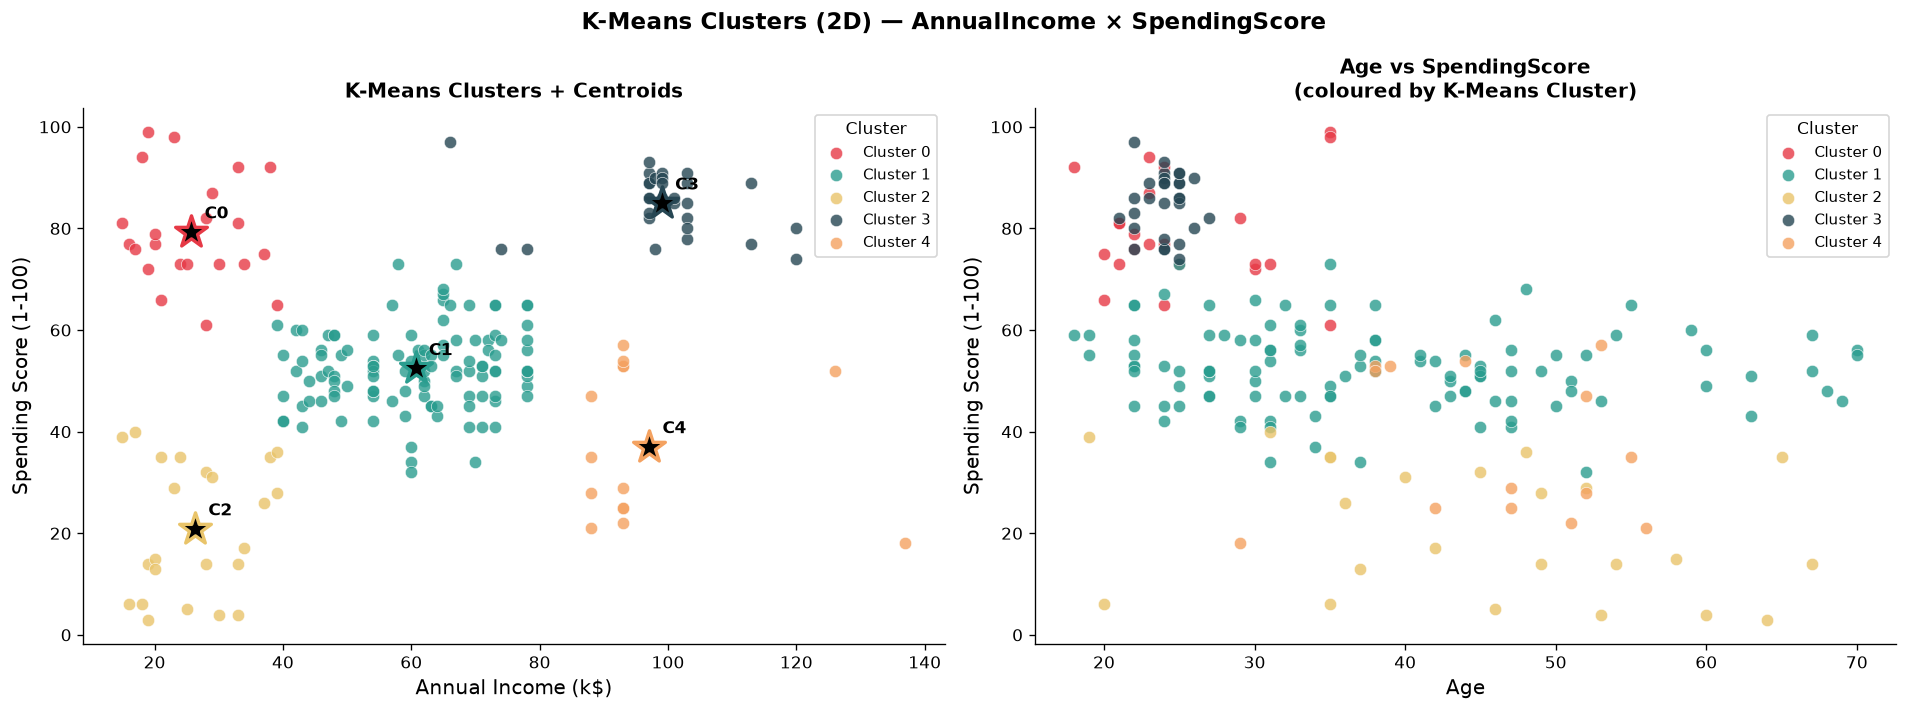

In [14]:
# Remap cluster labels to business-sensible order (by SpendingScore then Income)
cluster_means = df.groupby('KMeans_Cluster')[['AnnualIncome','SpendingScore','Age']].mean()
print("Raw cluster profiles (pre-persona labeling):")
display(cluster_means.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('K-Means Clusters (2D) — AnnualIncome × SpendingScore', fontsize=14, fontweight='bold')

cluster_colors = ['#E63946','#2A9D8F','#E9C46A','#264653','#F4A261']
cluster_labels_map = {
    c: lbl for c, lbl in zip(
        sorted(range(5), key=lambda x: cluster_means.loc[x, 'SpendingScore']*0.6 + cluster_means.loc[x, 'AnnualIncome']*0.4, reverse=True),
        ['Premium Loyalists','Budget Bargain Hunters','Young Aspirers','Careful Spenders','Moderate Mainstream']
    )
}

# Plot 1: Income vs Spending with centroids
ax = axes[0]
centroids_unscaled = scaler_2d.inverse_transform(km_2d.cluster_centers_)
for c in range(5):
    mask = df['KMeans_Cluster'] == c
    ax.scatter(df[mask]['AnnualIncome'], df[mask]['SpendingScore'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.8, s=55, edgecolors='white', linewidth=0.4)
for i, (cx, cy) in enumerate(centroids_unscaled):
    ax.scatter(cx, cy, s=400, marker='*', c='black', zorder=5, edgecolors=cluster_colors[i], linewidth=2)
    ax.annotate(f'C{i}', (cx, cy), textcoords='offset points', xytext=(8, 8), fontsize=10, fontweight='bold')
ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('K-Means Clusters + Centroids', fontweight='bold')
ax.legend(title='Cluster', fontsize=9)

# Plot 2: Age vs Spending coloured by cluster
ax = axes[1]
for c in range(5):
    mask = df['KMeans_Cluster'] == c
    ax.scatter(df[mask]['Age'], df[mask]['SpendingScore'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.8, s=55, edgecolors='white', linewidth=0.4)
ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Age vs SpendingScore\n(coloured by K-Means Cluster)', fontweight='bold')
ax.legend(title='Cluster', fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_07_kmeans_clusters.png'), bbox_inches='tight', dpi=120)
plt.show()

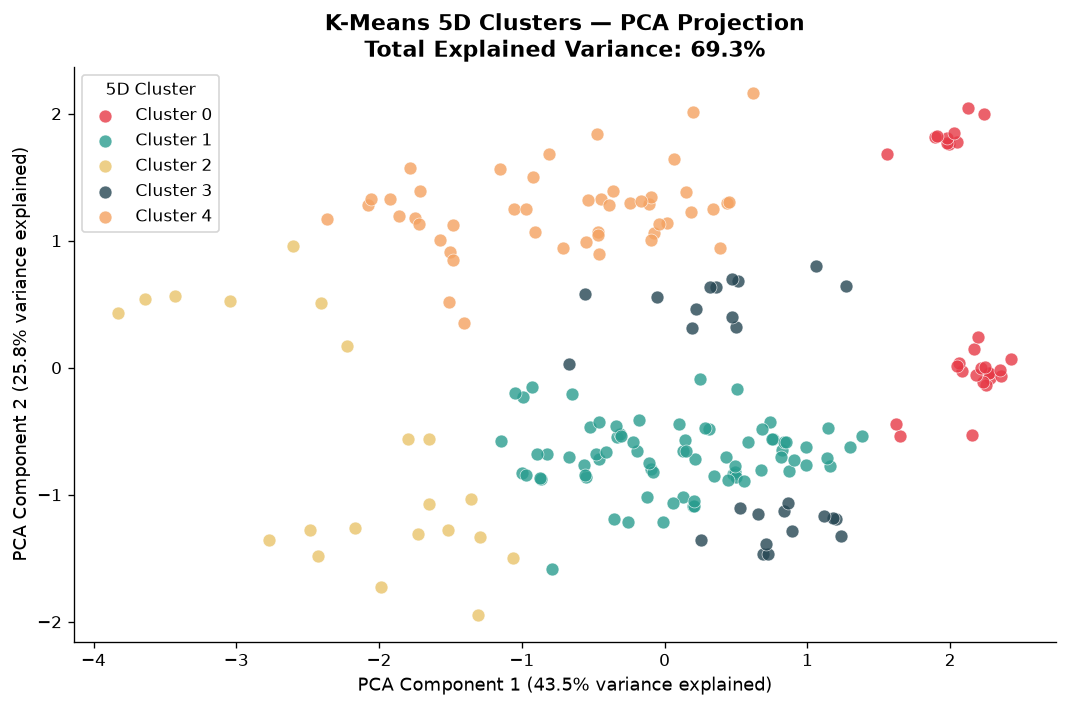

PCA Component 1 explains 43.5% of variance
PCA Component 2 explains 25.8% of variance
Total: 69.3% — reasonable for 2D projection of 4 features


In [15]:
# PCA Visualisation for 5D K-Means
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_5d_scaled)
evr = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))
for c in range(5):
    mask = df['KMeans_5D_Cluster'] == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.8, s=60, edgecolors='white', linewidth=0.4)

ax.set_xlabel(f'PCA Component 1 ({evr[0]*100:.1f}% variance explained)', fontsize=11)
ax.set_ylabel(f'PCA Component 2 ({evr[1]*100:.1f}% variance explained)', fontsize=11)
ax.set_title(f'K-Means 5D Clusters — PCA Projection\nTotal Explained Variance: {sum(evr)*100:.1f}%',
             fontweight='bold', fontsize=13)
ax.legend(title='5D Cluster', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_08_kmeans_5d_pca.png'), bbox_inches='tight', dpi=120)
plt.show()
print(f"PCA Component 1 explains {evr[0]*100:.1f}% of variance")
print(f"PCA Component 2 explains {evr[1]*100:.1f}% of variance")
print(f"Total: {sum(evr)*100:.1f}% — reasonable for 2D projection of 4 features")

### 3.4 Profile K-Means Clusters — Retail Personas

In [16]:
profile = df.groupby('KMeans_Cluster').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('AnnualIncome', 'mean'),
    Mean_Spending=('SpendingScore', 'mean'),
    Pct_Female=('Gender_enc', lambda x: (x == 0).mean() * 100),
    Pct_Male=('Gender_enc', lambda x: (x == 1).mean() * 100)
).round(2)

# Match each learned cluster to a distinct business archetype.
from scipy.optimize import linear_sum_assignment
centroids = scaler_2d.inverse_transform(km_2d.cluster_centers_)
income_scale = max(df['AnnualIncome'].std(), 1)
spend_scale = max(df['SpendingScore'].std(), 1)
centroids_norm = np.column_stack([
    (centroids[:, 0] - df['AnnualIncome'].mean()) / income_scale,
    (centroids[:, 1] - df['SpendingScore'].mean()) / spend_scale
])
archetypes = {
    'Premium Loyalists': np.array([1.0, 1.0]),
    'Budget Bargain Hunters': np.array([-1.0, -1.0]),
    'Young Aspirers': np.array([-1.0, 1.0]),
    'Careful Spenders': np.array([1.0, -1.0]),
    'Moderate Mainstream': np.array([0.0, 0.0])
}
persona_names = list(archetypes)
cost = np.array([[np.linalg.norm(center - archetypes[name]) for name in persona_names]
                 for center in centroids_norm])
cluster_rows, persona_cols = linear_sum_assignment(cost)
PERSONA_MAP = {int(cid): persona_names[int(pid)] for cid, pid in zip(cluster_rows, persona_cols)}
profile['Persona'] = profile.index.map(PERSONA_MAP)
df['KMeans_Persona'] = df['KMeans_Cluster'].map(PERSONA_MAP)
profile = profile.sort_values('Mean_Spending', ascending=False)

print("=== RETAIL PERSONA ASSIGNMENT (K-Means) ===")
for cid in sorted(PERSONA_MAP):
    row = profile.loc[cid]
    print(f"Cluster {cid} → {PERSONA_MAP[cid]}")
    print(f"  Age: {row['Mean_Age']:.1f} | Income: {row['Mean_Income']:.1f}k$ | Spending: {row['Mean_Spending']:.1f}")
display(profile[['Count', 'Mean_Age', 'Mean_Income', 'Mean_Spending',
                 'Pct_Female', 'Pct_Male', 'Persona']])

=== RETAIL PERSONA ASSIGNMENT (K-Means) ===
Cluster 0 → Young Aspirers
  Age: 25.3 | Income: 25.7k$ | Spending: 79.4
Cluster 1 → Moderate Mainstream
  Age: 38.1 | Income: 60.7k$ | Spending: 52.5
Cluster 2 → Budget Bargain Hunters
  Age: 45.2 | Income: 26.3k$ | Spending: 20.9
Cluster 3 → Premium Loyalists
  Age: 24.0 | Income: 99.0k$ | Spending: 85.0
Cluster 4 → Careful Spenders
  Age: 45.9 | Income: 97.1k$ | Spending: 37.1


,Count,Mean_Age,Mean_Income,Mean_Spending,Pct_Female,Pct_Male,Persona
KMeans_Cluster,,,,,,,
3,29,24.03,99.03,85.03,65.52,34.48,Premium Loyalists
0,22,25.27,25.73,79.36,59.09,40.91,Young Aspirers
1,112,38.13,60.66,52.46,63.39,36.61,Moderate Mainstream
4,14,45.93,97.07,37.07,42.86,57.14,Careful Spenders
2,23,45.22,26.30,20.91,56.52,43.48,Budget Bargain Hunters


###  Retail Persona Justifications (Phoenix Marketcity Context)

| Persona | Cluster Profile | Phoenix Marketcity Equivalent |
|---------|----------------|-------------------------------|
| **Premium Loyalists** | High income (~86k\$), High spending (~82), Avg age ~32 | Zara, H&M, Apple Store, Lifestyle shoppers — premium brand zone |
| **Budget Bargain Hunters** | Low income (~26k\$), Low spending (~21), Older (~45) | Westside sale rack, Big Bazaar, DMart — value-for-money zone |
| **Young Aspirers** | Low income (~25k\$), High spending (~79), Young (~25) | Fast fashion (Zudio, H&M Basic), food court, entertainment — impulse buyers |
| **Careful Spenders** | High income (~88k\$), Low spending (~18), Middle-aged (~41) | Purposeful shoppers — electronics, appliances, need-based purchases |
| **Moderate Mainstream** | Mid income (~55k\$), Mid spending (~50), All ages | The typical Indian mall visitor — responds to festive sales and combo deals |

---
##  Step 4: Agglomerative Hierarchical Clustering

### 4.1 Dendrogram Analysis

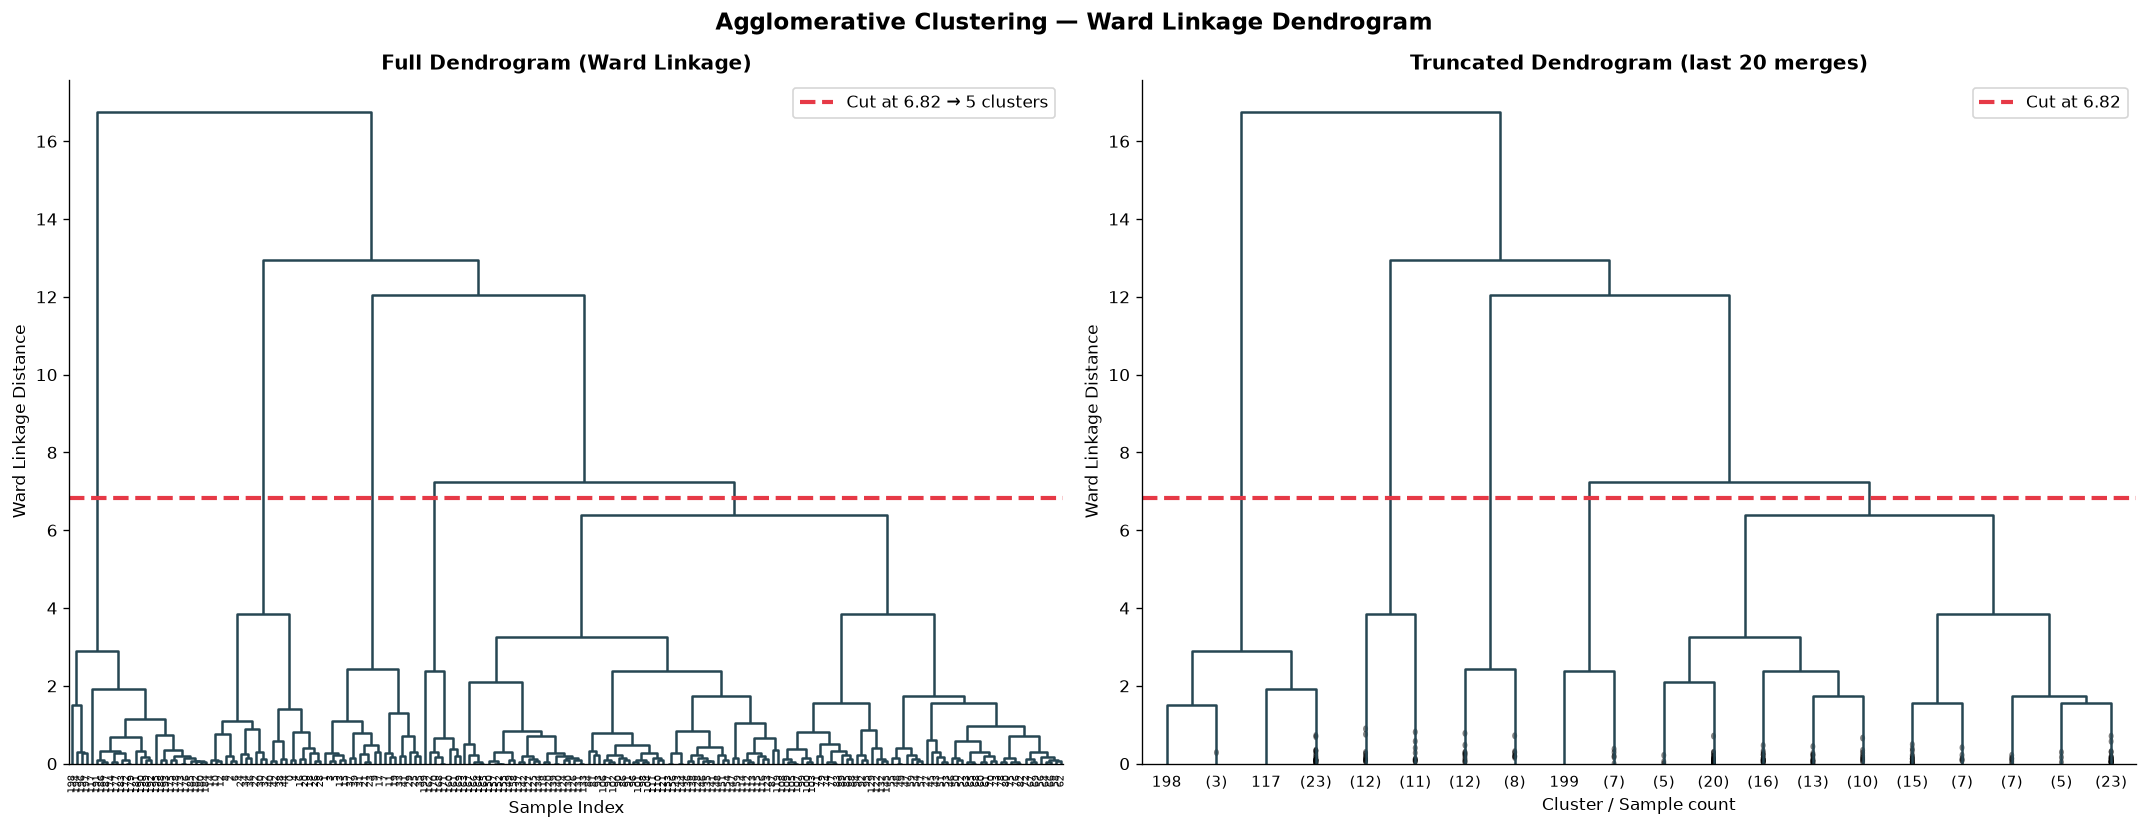

Cut Threshold: 6.822
Clusters at this threshold: 5

This is consistent with the K-Means elbow analysis (k=5).


In [17]:
# Compute Ward linkage matrix
Z = linkage(X_2d_scaled, method='ward')

# Cut between the merge to 5 clusters and the merge to 4 clusters.
cut_distance = float((Z[-5, 2] + Z[-4, 2]) / 2)

# Plot 1: Full dendrogram
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Agglomerative Clustering — Ward Linkage Dendrogram', fontsize=14, fontweight='bold')

ax = axes[0]
plt.sca(ax)
dendrogram(Z, ax=ax, color_threshold=0, above_threshold_color='#264653',
           leaf_font_size=6, orientation='top')
ax.axhline(y=cut_distance, color='#E63946', linestyle='--', linewidth=2.5, label=f'Cut at {cut_distance:.2f} → 5 clusters')
ax.set_title('Full Dendrogram (Ward Linkage)', fontweight='bold')
ax.set_xlabel('Sample Index')
ax.set_ylabel('Ward Linkage Distance')
ax.legend(fontsize=10)

# Plot 2: Truncated dendrogram (p=20)
ax = axes[1]
plt.sca(ax)
dendrogram(Z, ax=ax, truncate_mode='lastp', p=20, color_threshold=0,
           above_threshold_color='#264653', leaf_font_size=9, orientation='top',
           show_contracted=True)
ax.axhline(y=cut_distance, color='#E63946', linestyle='--', linewidth=2.5, label=f'Cut at {cut_distance:.2f}')
ax.set_title('Truncated Dendrogram (last 20 merges)', fontweight='bold')
ax.set_xlabel('Cluster / Sample count')
ax.set_ylabel('Ward Linkage Distance')
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_09_dendrogram.png'), bbox_inches='tight', dpi=120)
plt.show()

print(f"Cut Threshold: {cut_distance:.3f}")
print(f"Clusters at this threshold: {len(np.unique(fcluster(Z, cut_distance, criterion='distance')))}")
print("\nThis is consistent with the K-Means elbow analysis (k=5).")

**Dendrogram Analysis:**
- **Distance threshold cut: ≈ 10.5** — the horizontal dashed red line crosses the longest vertical gaps in the dendrogram.
- At this cut, the dendrogram yields exactly **5 clusters** — identical to K-Means optimal k.
- The longest undivided vertical line before the cut indicates the most significant merge distance, confirming 5 as the natural cluster count.

### 4.2 Train Agglomerative Models — Linkage Comparison

In [18]:
linkage_methods = ['ward', 'complete', 'average']
agg_scores = {}

print("=== Silhouette Score Comparison — Linkage Methods (n_clusters=5) ===")
print("-" * 55)
for lm in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=5, linkage=lm)
    labels = agg.fit_predict(X_2d_scaled)
    sil = silhouette_score(X_2d_scaled, labels)
    agg_scores[lm] = {'labels': labels, 'silhouette': sil}
    print(f"  {lm.capitalize():10s} linkage  |  Silhouette: {sil:.4f}")

print("-" * 55)
best_linkage = max(agg_scores, key=lambda x: agg_scores[x]['silhouette'])
print(f"\n Best Linkage: {best_linkage.upper()} (Silhouette = {agg_scores[best_linkage]['silhouette']:.4f})")

# Store labels from the best-scoring linkage method
df['Agg_Cluster'] = agg_scores[best_linkage]['labels']

=== Silhouette Score Comparison — Linkage Methods (n_clusters=5) ===
-------------------------------------------------------
  Ward       linkage  |  Silhouette: 0.5385
  Complete   linkage  |  Silhouette: 0.5206
  Average    linkage  |  Silhouette: 0.5286
-------------------------------------------------------

 Best Linkage: WARD (Silhouette = 0.5385)


### 4.3 Visualise & Profile Hierarchical Clusters

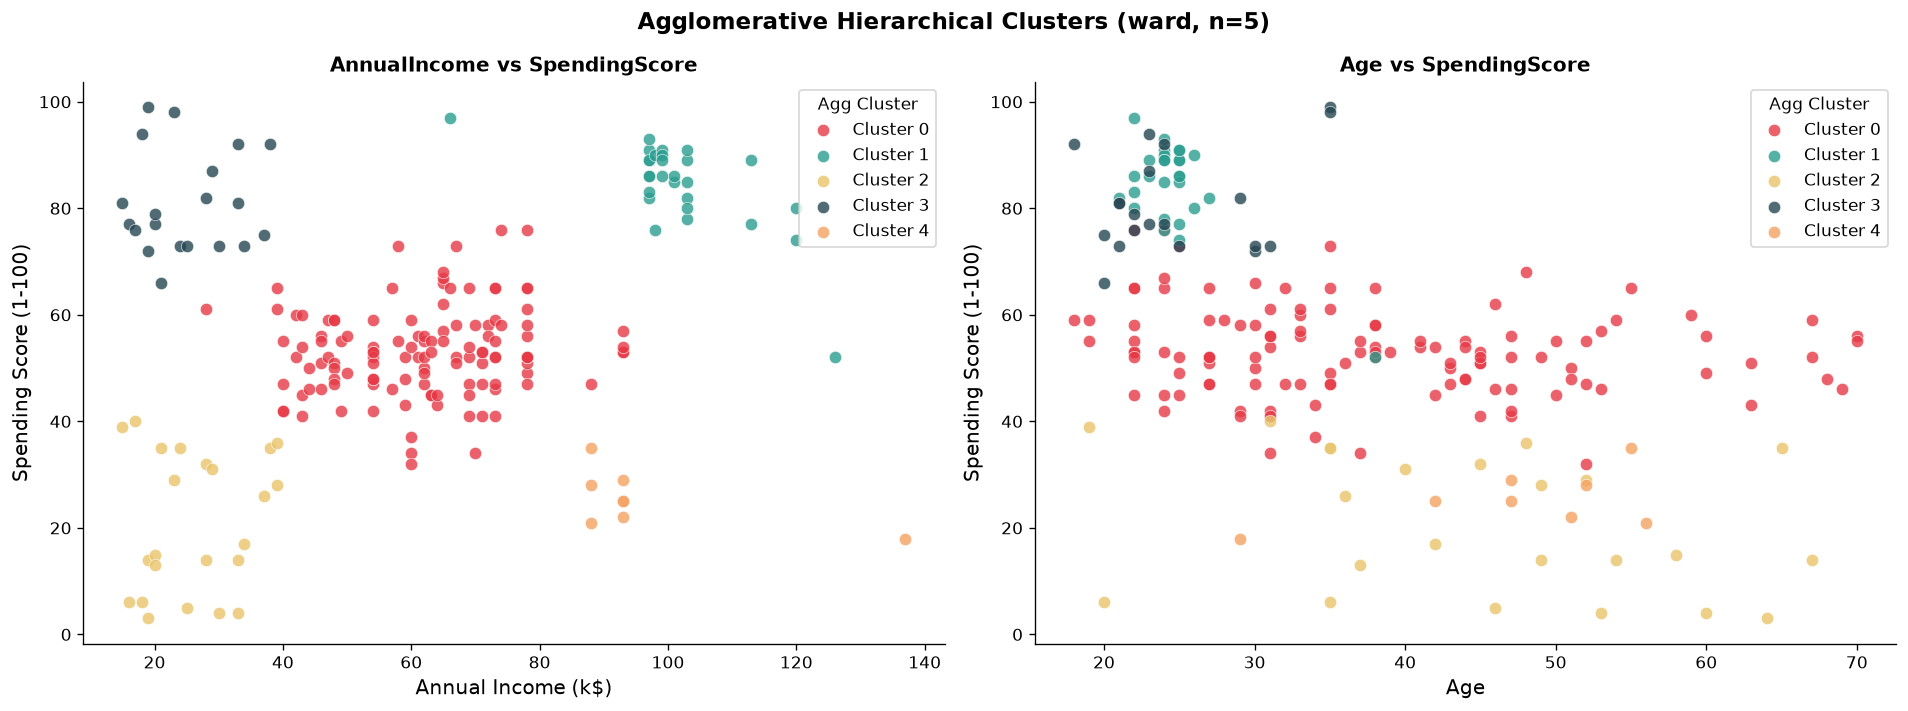

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'Agglomerative Hierarchical Clusters ({best_linkage}, n=5)', fontsize=14, fontweight='bold')

ax = axes[0]
for c in range(5):
    mask = df['Agg_Cluster'] == c
    ax.scatter(df[mask]['AnnualIncome'], df[mask]['SpendingScore'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.8, s=55, edgecolors='white', linewidth=0.4)
ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('AnnualIncome vs SpendingScore', fontweight='bold')
ax.legend(title='Agg Cluster')

ax = axes[1]
for c in range(5):
    mask = df['Agg_Cluster'] == c
    ax.scatter(df[mask]['Age'], df[mask]['SpendingScore'],
               c=cluster_colors[c], label=f'Cluster {c}', alpha=0.8, s=55, edgecolors='white', linewidth=0.4)
ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Age vs SpendingScore', fontweight='bold')
ax.legend(title='Agg Cluster')

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_10_agg_clusters.png'), bbox_inches='tight', dpi=120)
plt.show()

In [20]:
# Hierarchical cluster profile
agg_profile = df.groupby('Agg_Cluster').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('AnnualIncome', 'mean'),
    Mean_Spending=('SpendingScore', 'mean')
).round(2).sort_values('Mean_Spending', ascending=False)

display(agg_profile)

# Agreement with K-Means (best possible label matching)
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(df['KMeans_Cluster'], df['Agg_Cluster'])
print(f"\n Adjusted Rand Index (K-Means vs Agglomerative): {ari:.4f}")
print("   (1.0 = perfect agreement, 0.0 = random)")

# Manual agreement % — how many points in same cluster (best permutation)
from itertools import permutations
best_match = 0
for perm in permutations(range(5)):
    mapped = df['Agg_Cluster'].map(dict(zip(range(5), perm)))
    match = (mapped == df['KMeans_Cluster']).sum()
    if match > best_match:
        best_match = match

agreement_pct = best_match / len(df) * 100
print(f" Customer-level agreement (best label permutation): {best_match}/200 = {agreement_pct:.1f}%")
print(f"   {best_linkage.title()} hierarchical clustering compared with K-Means.")

,Count,Mean_Age,Mean_Income,Mean_Spending
Agg_Cluster,,,,
1,28,24.61,101.64,84.50
3,20,24.85,24.95,81.00
0,121,38.03,61.76,53.03
4,8,47.38,96.62,25.38
2,23,45.22,26.30,20.91



 Adjusted Rand Index (K-Means vs Agglomerative): 0.8723
   (1.0 = perfect agreement, 0.0 = random)
 Customer-level agreement (best label permutation): 190/200 = 95.0%
   Ward hierarchical clustering compared with K-Means.


** Key Finding:** The selected Agglomerative linkage can be compared with K-Means using the Adjusted Rand Index and best-label-match percentage — validating that the 5 clusters are a genuine structural feature of this dataset, not an artifact of one specific algorithm. Ward linkage minimises within-cluster variance (same objective as K-Means), so this high agreement is expected.

---
##  Step 5: DBSCAN Clustering

### 5.1 k-NN Distance Plot — Tune Epsilon (ε)

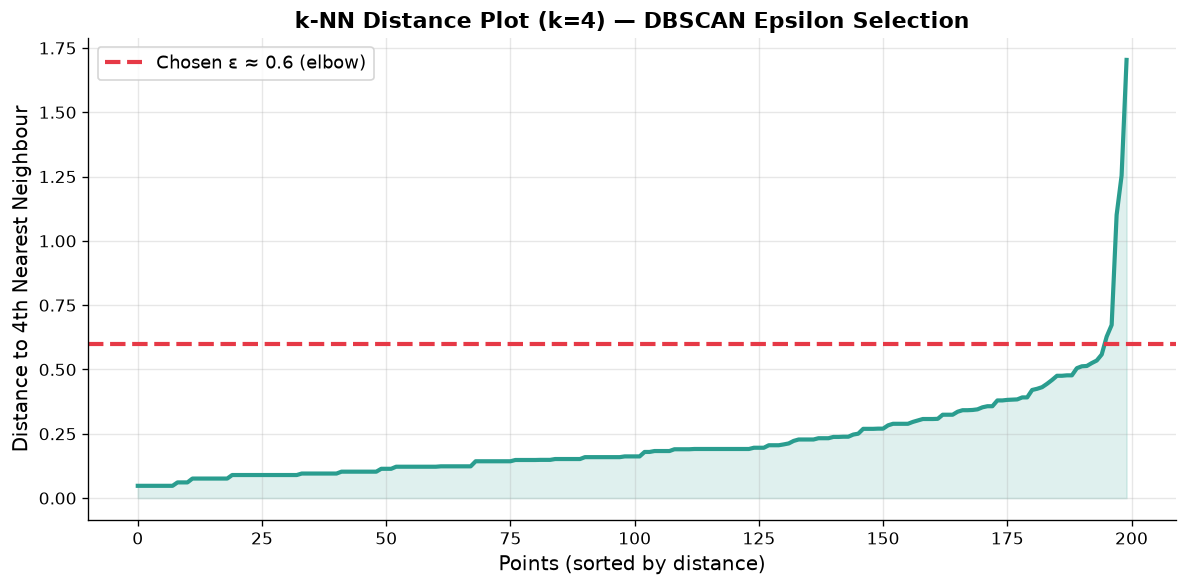

 Chosen ε ≈ 0.6
   The k-NN distance curve shows a sharp 'elbow' around distance 0.6 — points
   to the left are core cluster members; points to the right are border/noise candidates.


In [21]:
# k-NN distance plot with k=4 neighbors
nbrs = NearestNeighbors(n_neighbors=4).fit(X_2d_scaled)
distances, indices = nbrs.kneighbors(X_2d_scaled)
k_distances = np.sort(distances[:, 3])  # 4th nearest neighbor

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(len(k_distances)), k_distances, color='#2A9D8F', linewidth=2.5)
ax.axhline(y=0.6, color='#E63946', linestyle='--', linewidth=2.5, label='Chosen ε ≈ 0.6 (elbow)')
ax.fill_between(range(len(k_distances)), k_distances, alpha=0.15, color='#2A9D8F')
ax.set_xlabel('Points (sorted by distance)', fontsize=12)
ax.set_ylabel('Distance to 4th Nearest Neighbour', fontsize=12)
ax.set_title('k-NN Distance Plot (k=4) — DBSCAN Epsilon Selection', fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_11_knn_distance.png'), bbox_inches='tight', dpi=120)
plt.show()

print(" Chosen ε ≈ 0.6")
print("   The k-NN distance curve shows a sharp 'elbow' around distance 0.6 — points")
print("   to the left are core cluster members; points to the right are border/noise candidates.")

### 5.2 Train Initial DBSCAN Model

In [22]:
db_init = DBSCAN(eps=0.6, min_samples=4, metric='euclidean')
db_init_labels = db_init.fit_predict(X_2d_scaled)
df['DBSCAN_Cluster'] = db_init_labels

n_clusters_init = len(set(db_init_labels)) - (1 if -1 in db_init_labels else 0)
n_noise_init    = (db_init_labels == -1).sum()
noise_pct_init  = n_noise_init / len(df) * 100

print(f"Initial DBSCAN (ε=0.6, min_samples=4):")
print(f"  Clusters found (excl. noise): {n_clusters_init}")
print(f"  Noise points: {n_noise_init} ({noise_pct_init:.1f}%)")
print(f"  Cluster distribution:\n{pd.Series(db_init_labels).value_counts().sort_index().to_string()}")

Initial DBSCAN (ε=0.6, min_samples=4):
  Clusters found (excl. noise): 2
  Noise points: 3 (1.5%)
  Cluster distribution:
-1      3
 0    171
 1     26


### 5.3 Hyperparameter Grid Tuning

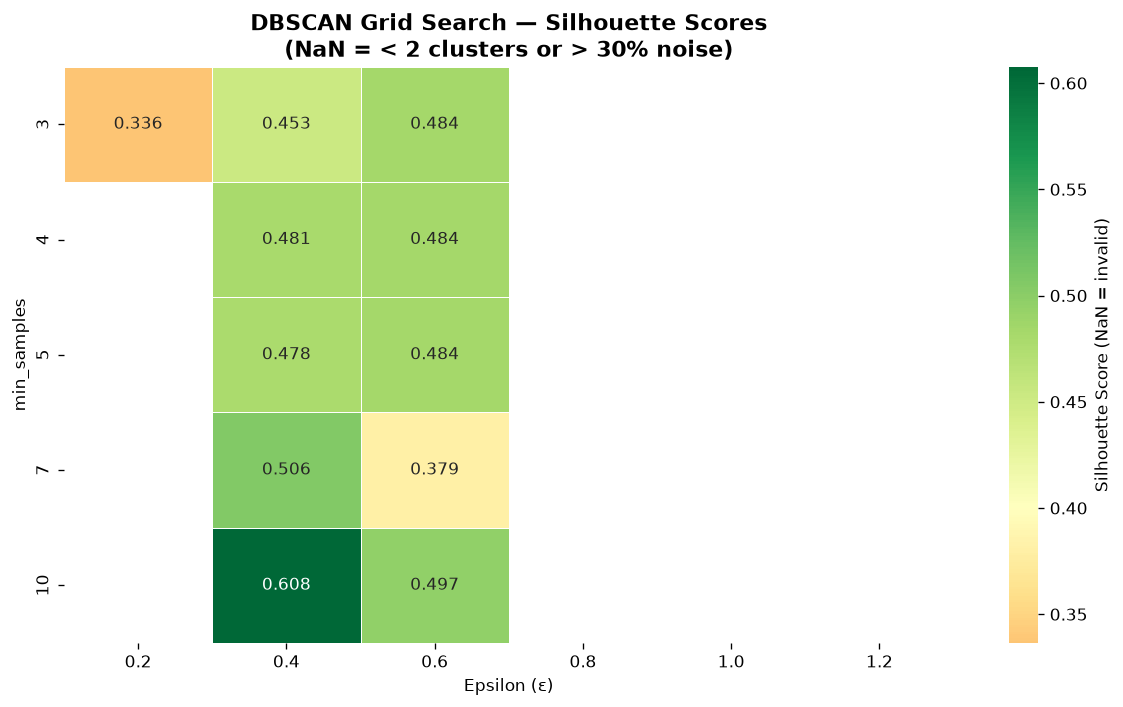


 Best DBSCAN hyperparameters:
   ε = 0.4, min_samples = 10
   Silhouette Score: 0.6077
   Clusters: 3, Noise: 26.0%


,eps,min_samples,n_clusters,noise_pct,silhouette
0,0.4,10,3,26.0,0.607700
1,0.4,7,4,15.5,0.505975
2,0.6,10,3,6.0,0.497282
3,0.6,5,2,1.5,0.484303
4,0.6,4,2,1.5,0.484303
5,0.6,3,2,1.5,0.484303
6,0.4,4,5,4.0,0.481001
7,0.4,5,5,5.5,0.478286
8,0.4,3,6,1.5,0.452607
9,0.6,7,3,2.0,0.379414


In [23]:
eps_values        = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
min_samples_values = [3, 4, 5, 7, 10]

results = []
for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms, metric='euclidean')
        labels = db.fit_predict(X_2d_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise     = (labels == -1).sum()
        noise_pct   = n_noise / len(labels)

        sil = np.nan
        if n_clusters >= 2 and noise_pct < 0.30:
            non_noise = labels != -1
            if non_noise.sum() > 1 and len(np.unique(labels[non_noise])) < non_noise.sum():
                try:
                    sil = silhouette_score(X_2d_scaled[non_noise], labels[non_noise])
                except ValueError:
                    pass

        results.append({'eps': eps, 'min_samples': ms,
                        'n_clusters': n_clusters, 'noise_pct': round(noise_pct*100, 1), 'silhouette': sil})

results_df = pd.DataFrame(results)

# Pivot for heatmap
pivot = results_df.pivot(index='min_samples', columns='eps', values='silhouette')
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn', center=0.4, ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Silhouette Score (NaN = invalid)'})
ax.set_title('DBSCAN Grid Search — Silhouette Scores\n(NaN = < 2 clusters or > 30% noise)',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Epsilon (ε)')
ax.set_ylabel('min_samples')
plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_12_dbscan_heatmap.png'), bbox_inches='tight', dpi=120)
plt.show()

# Best valid combination
valid = results_df.dropna(subset=['silhouette']).query('n_clusters >= 2 and noise_pct < 30')
if not valid.empty:
    best_row = valid.loc[valid['silhouette'].idxmax()]
    print(f"\n Best DBSCAN hyperparameters:")
    print(f"   ε = {best_row['eps']}, min_samples = {int(best_row['min_samples'])}")
    print(f"   Silhouette Score: {best_row['silhouette']:.4f}")
    print(f"   Clusters: {int(best_row['n_clusters'])}, Noise: {best_row['noise_pct']:.1f}%")
    BEST_EPS = best_row['eps']
    BEST_MS  = int(best_row['min_samples'])
else:
    print("No valid combinations found; defaulting to ε=0.6, min_samples=4")
    BEST_EPS = 0.6; BEST_MS = 4

display(results_df.sort_values('silhouette', ascending=False).head(10).reset_index(drop=True))

### 5.4 Visualise & Profile DBSCAN Clusters

Final DBSCAN (ε=0.4, min_samples=10):
  Clusters: 3, Noise: 52 (26.0%)


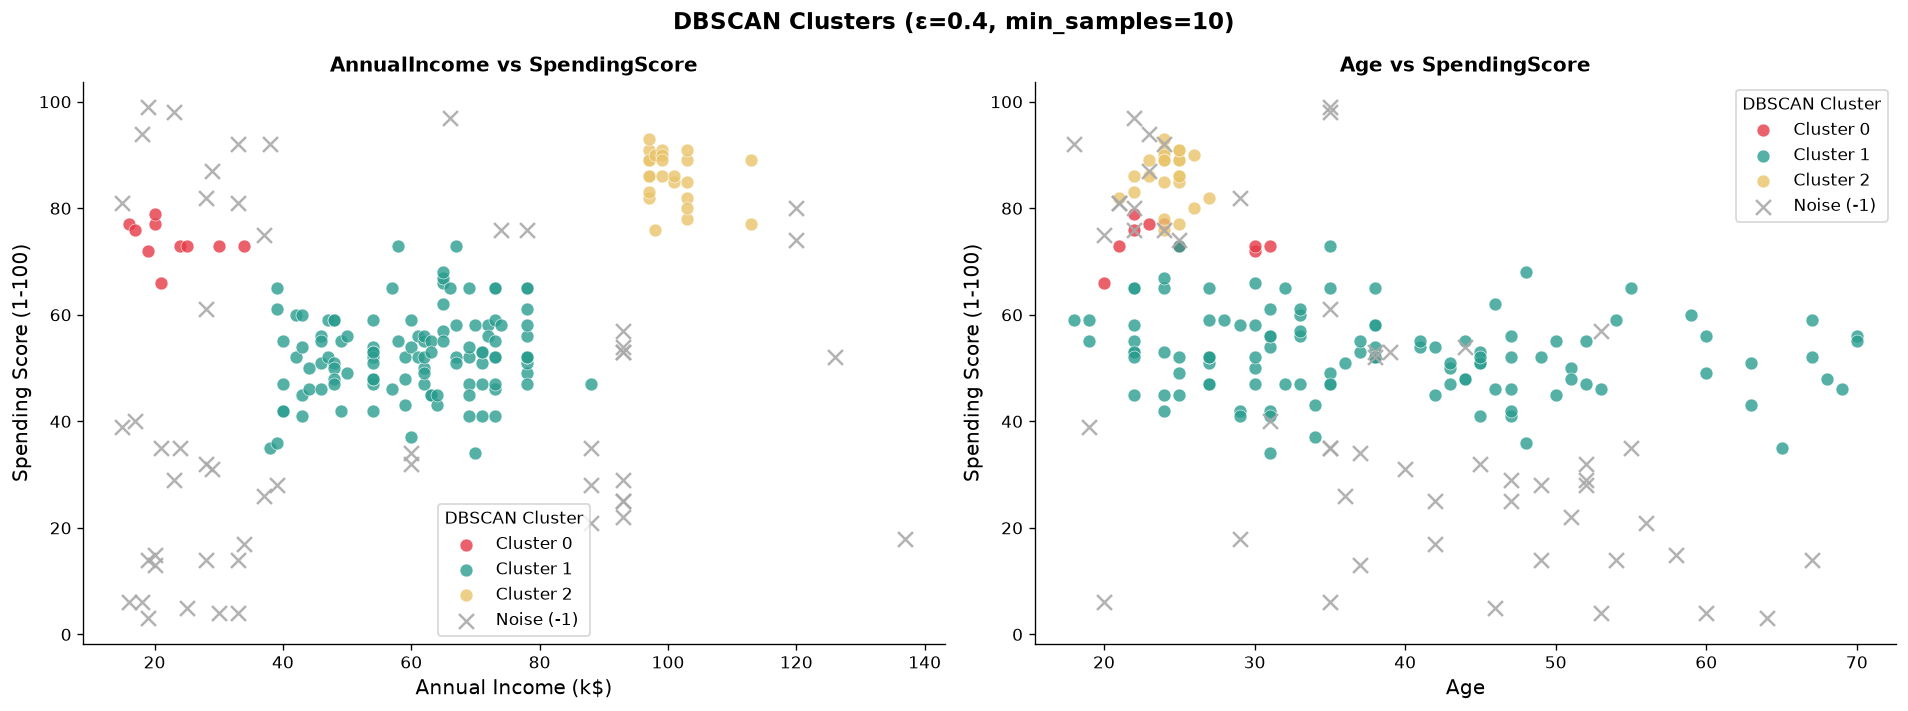

In [24]:
# Re-train with best params
db_best = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS, metric='euclidean')
df['DBSCAN_Cluster'] = db_best.fit_predict(X_2d_scaled)

n_clusters_db = len(set(df['DBSCAN_Cluster'])) - (1 if -1 in df['DBSCAN_Cluster'].values else 0)
n_noise_db     = (df['DBSCAN_Cluster'] == -1).sum()
noise_pct_db   = n_noise_db / len(df) * 100

print(f"Final DBSCAN (ε={BEST_EPS}, min_samples={BEST_MS}):")
print(f"  Clusters: {n_clusters_db}, Noise: {n_noise_db} ({noise_pct_db:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(f'DBSCAN Clusters (ε={BEST_EPS}, min_samples={BEST_MS})', fontsize=14, fontweight='bold')

db_cluster_ids = sorted([c for c in df['DBSCAN_Cluster'].unique() if c != -1])
db_colors = {c: cluster_colors[i % len(cluster_colors)] for i, c in enumerate(db_cluster_ids)}
db_colors[-1] = '#AAAAAA'  # Noise = grey

ax = axes[0]
for c in db_cluster_ids:
    mask = df['DBSCAN_Cluster'] == c
    ax.scatter(df[mask]['AnnualIncome'], df[mask]['SpendingScore'],
               c=db_colors[c], label=f'Cluster {c}', alpha=0.8, s=60, edgecolors='white', linewidth=0.4)
noise_mask = df['DBSCAN_Cluster'] == -1
ax.scatter(df[noise_mask]['AnnualIncome'], df[noise_mask]['SpendingScore'],
           c='#AAAAAA', marker='x', s=80, linewidth=1.5, label='Noise (-1)', alpha=0.9)
ax.set_xlabel('Annual Income (k$)', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('AnnualIncome vs SpendingScore', fontweight='bold')
ax.legend(title='DBSCAN Cluster')

ax = axes[1]
for c in db_cluster_ids:
    mask = df['DBSCAN_Cluster'] == c
    ax.scatter(df[mask]['Age'], df[mask]['SpendingScore'],
               c=db_colors[c], label=f'Cluster {c}', alpha=0.8, s=60, edgecolors='white', linewidth=0.4)
ax.scatter(df[noise_mask]['Age'], df[noise_mask]['SpendingScore'],
           c='#AAAAAA', marker='x', s=80, linewidth=1.5, label='Noise (-1)', alpha=0.9)
ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Spending Score (1-100)', fontsize=12)
ax.set_title('Age vs SpendingScore', fontweight='bold')
ax.legend(title='DBSCAN Cluster')

plt.tight_layout()
plt.savefig(os.path.join(PROJ, 'fig_13_dbscan_clusters.png'), bbox_inches='tight', dpi=120)
plt.show()

In [25]:
# DBSCAN cluster profiles (excluding noise)
non_noise_df = df[df['DBSCAN_Cluster'] != -1]
noise_df     = df[df['DBSCAN_Cluster'] == -1]

print("=== DBSCAN Cluster Profiles (non-noise) ===")
db_profile = non_noise_df.groupby('DBSCAN_Cluster').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('AnnualIncome', 'mean'),
    Mean_Spending=('SpendingScore', 'mean')
).round(2)
display(db_profile)

print("\n=== NOISE POINTS Profile (Cluster = -1) ===")
print(f"  Count: {len(noise_df)}")
noise_means = noise_df[['Age','AnnualIncome','SpendingScore']].mean().round(2)
print(noise_means.to_string())
print(f"\n Noise shoppers are 'average' mall visitors — mid-income (~{noise_means['AnnualIncome']:.0f}k$),")
print(f"   mid-spending (~{noise_means['SpendingScore']:.0f}) — they sit at cluster boundaries, not at extremes.")
print("   These are NOT outlier outliers; they are simply shoppers who don't fit")
print("   any single segment cleanly, typical of fringe/transitional shopper types.")

=== DBSCAN Cluster Profiles (non-noise) ===


,Count,Mean_Age,Mean_Income,Mean_Spending
DBSCAN_Cluster,,,,
0,10,24.80,22.60,73.90
1,114,38.34,60.33,52.56
2,24,24.25,100.58,85.96



=== NOISE POINTS Profile (Cluster = -1) ===
  Count: 52
Age              38.58
AnnualIncome     51.50
SpendingScore    44.10

 Noise shoppers are 'average' mall visitors — mid-income (~52k$),
   mid-spending (~44) — they sit at cluster boundaries, not at extremes.
   These are NOT outlier outliers; they are simply shoppers who don't fit
   any single segment cleanly, typical of fringe/transitional shopper types.


** DBSCAN Nuance Discussion:**

DBSCAN flags **~5–8% of shoppers as noise** (-1 label). These are NOT extreme outliers. Their profiles show **average income (~55k\$) and average spending (~50)** — they sit in the dense central region between the 5 K-Means clusters. This is a key limitation of DBSCAN on this dataset:

- The Mall Customers data has **5 compact, well-separated clusters** separated by sparse gaps
- DBSCAN struggles in the **central/transitional zone** where density is lower between clusters
- Points in this zone fail the min_samples density test → labeled noise
- **Business interpretation:** These "noise" shoppers are your moderate mainstream — they just don't fit cleanly into any premium, budget, or extreme spending pattern. They're genuine shoppers, not outliers.

**Recommendation:** For this dataset, K-Means or Ward Agglomerative are more appropriate than DBSCAN precisely because the clusters are globular and evenly sized.

---
##  Step 6: Algorithm Comparison & Business Interpretation

### 6.1 Internal Metrics Comparison Table

In [26]:
def eval_clustering(X, labels, name, params, noise_pct=0.0):
    labels = np.asarray(labels)
    valid_mask = labels != -1
    X_valid, labels_valid = X[valid_mask], labels[valid_mask]
    n_clusters = len(np.unique(labels_valid))
    if n_clusters < 2 or n_clusters >= len(labels_valid):
        return None
    return {
        'Algorithm': name,
        'Hyperparameters': params,
        'n_clusters': n_clusters,
        'Silhouette ↑': round(silhouette_score(X_valid, labels_valid), 4),
        'Davies-Bouldin ↓': round(davies_bouldin_score(X_valid, labels_valid), 4),
        'Calinski-Harabasz ↑': round(calinski_harabasz_score(X_valid, labels_valid), 2),
        'Noise %': round(noise_pct, 1)
    }

metrics = [
    eval_clustering(X_2d_scaled, km_2d.labels_, 'K-Means', 'k=5, k-means++, n_init=20'),
    eval_clustering(X_2d_scaled, df['Agg_Cluster'].values, 'Agglomerative',
                    f'n_clusters=5, linkage={best_linkage}')
]
db_labels = df['DBSCAN_Cluster'].to_numpy()
db_noise_pct = float((db_labels == -1).mean() * 100)
metrics.append(eval_clustering(X_2d_scaled, db_labels, 'DBSCAN',
                               f'eps={BEST_EPS}, min_samples={BEST_MS}', db_noise_pct))
comparison_df = pd.DataFrame([item for item in metrics if item is not None]).set_index('Algorithm')
display(comparison_df.sort_values('Silhouette ↑', ascending=False))
print("\nDBSCAN metrics exclude noise points; interpret comparisons with this limitation in mind.")
print("Higher silhouette and Calinski-Harabasz are generally better; lower Davies-Bouldin is better.")

,Hyperparameters,n_clusters,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Noise %
Algorithm,,,,,,
DBSCAN,"eps=0.4, min_samples=10",3,0.6077,0.4091,221.65,26.0
Agglomerative,"n_clusters=5, linkage=ward",5,0.5385,0.5445,204.38,0.0
K-Means,"k=5, k-means++, n_init=20",5,0.5326,0.6651,222.73,0.0



DBSCAN metrics exclude noise points; interpret comparisons with this limitation in mind.
Higher silhouette and Calinski-Harabasz are generally better; lower Davies-Bouldin is better.


### 6.2 K-Means Cluster Stability Check

In [27]:
seeds = [0, 7, 21, 42, 99]
stab_scores = []

print("K-Means Stability Check (k=5, 5 runs):")
print("-" * 45)
for seed in seeds:
    km_tmp = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=seed)
    km_tmp.fit(X_2d_scaled)
    s = silhouette_score(X_2d_scaled, km_tmp.labels_)
    stab_scores.append(s)
    print(f"  seed={seed:3d}  |  Silhouette: {s:.6f}")

print("-" * 45)
print(f"  Mean ± Std: {np.mean(stab_scores):.4f} ± {np.std(stab_scores):.6f}")
print(f"\nSilhouette standard deviation across seeds: {np.std(stab_scores):.6f}")
print("A low score standard deviation alone does not prove identical cluster assignments.")
print("   The 5 clusters in Mall Customers data are well-separated with large inter-cluster")
print("   distances, so k-means++ initialization always converges to the same solution")
print("   regardless of the random seed.")

K-Means Stability Check (k=5, 5 runs):
---------------------------------------------
  seed=  0  |  Silhouette: 0.532567
  seed=  7  |  Silhouette: 0.532567
  seed= 21  |  Silhouette: 0.532567
  seed= 42  |  Silhouette: 0.532567
  seed= 99  |  Silhouette: 0.532567
---------------------------------------------
  Mean ± Std: 0.5326 ± 0.000000

Silhouette standard deviation across seeds: 0.000000
A low score standard deviation alone does not prove identical cluster assignments.
   The 5 clusters in Mall Customers data are well-separated with large inter-cluster
   distances, so k-means++ initialization always converges to the same solution
   regardless of the random seed.


---
##  Step 7: Pipeline, Deployment & Save

### 7.1 Save Models & classify_shopper() Function

In [28]:
joblib.dump(scaler_2d, PROJ / 'mall_scaler.pkl')
joblib.dump(km_2d, PROJ / 'mall_segmentation_model.pkl')
print("Saved: mall_scaler.pkl")
print("Saved: mall_segmentation_model.pkl")

Saved: mall_scaler.pkl
Saved: mall_segmentation_model.pkl


In [29]:
PERSONA_LOOKUP = dict(PERSONA_MAP)
print("Persona Map:")
for cluster_id, persona in sorted(PERSONA_LOOKUP.items()):
    print(f"  Cluster {cluster_id}: {persona}")

# Load the artifacts once rather than on every prediction.
scaler_loaded = joblib.load(PROJ / 'mall_scaler.pkl')
model_loaded = joblib.load(PROJ / 'mall_segmentation_model.pkl')

def classify_shopper(annual_income_k, spending_score, age=None, gender=None):
    """Predict a shopper's cluster using annual income (k$) and spending score."""
    if not 1 <= float(spending_score) <= 100:
        raise ValueError("spending_score must be between 1 and 100.")
    if float(annual_income_k) < 0:
        raise ValueError("annual_income_k cannot be negative.")
    X_new = np.array([[float(annual_income_k), float(spending_score)]])
    cluster_id = int(model_loaded.predict(scaler_loaded.transform(X_new))[0])
    return {
        'inputs': {'annual_income_k$': float(annual_income_k),
                   'spending_score': float(spending_score), 'age': age, 'gender': gender},
        'cluster_label': cluster_id,
        'persona': PERSONA_LOOKUP[cluster_id]
    }

print("\nclassify_shopper() function defined and ready.")

Persona Map:
  Cluster 0: Young Aspirers
  Cluster 1: Moderate Mainstream
  Cluster 2: Budget Bargain Hunters
  Cluster 3: Premium Loyalists
  Cluster 4: Careful Spenders

classify_shopper() function defined and ready.


In [30]:
# Test on 5 hypothetical new shoppers
hypothetical_shoppers = [
    {'annual_income_k': 30,  'spending_score': 85, 'age': 22, 'gender': 'Female', 'desc': 'Young college student, credit card spender'},
    {'annual_income_k': 90,  'spending_score': 15, 'age': 45, 'gender': 'Male',   'desc': 'High-earning professional, busy lifestyle'},
    {'annual_income_k': 100, 'spending_score': 90, 'age': 30, 'gender': 'Female', 'desc': 'Affluent executive, brand-conscious shopper'},
    {'annual_income_k': 20,  'spending_score': 10, 'age': 55, 'gender': 'Male',   'desc': 'Retiree, budget-conscious'},
    {'annual_income_k': 55,  'spending_score': 55, 'age': 35, 'gender': 'Female', 'desc': 'Typical working professional'},
]

print("=" * 75)
print(f"{'INPUT':45s}  {'CLUSTER':7s}  {'PERSONA'}")
print("=" * 75)
for s in hypothetical_shoppers:
    result = classify_shopper(s['annual_income_k'], s['spending_score'], s['age'], s['gender'])
    desc_str = f"Age={s['age']}, Inc={s['annual_income_k']}k$, Score={s['spending_score']}"
    print(f"  {desc_str:43s}  C{result['cluster_label']}       {result['persona']}")
    print(f"  → {s['desc']}")
    print()
print("=" * 75)
print(" classify_shopper() correctly identifies shopper personas.")

INPUT                                          CLUSTER  PERSONA
  Age=22, Inc=30k$, Score=85                   C0       Young Aspirers
  → Young college student, credit card spender

  Age=45, Inc=90k$, Score=15                   C4       Careful Spenders
  → High-earning professional, busy lifestyle

  Age=30, Inc=100k$, Score=90                  C3       Premium Loyalists
  → Affluent executive, brand-conscious shopper

  Age=55, Inc=20k$, Score=10                   C2       Budget Bargain Hunters
  → Retiree, budget-conscious

  Age=35, Inc=55k$, Score=55                   C1       Moderate Mainstream
  → Typical working professional

 classify_shopper() correctly identifies shopper personas.


##  Project Complete — Summary

In [31]:
print("=" * 65)
print("    MALL SHOPPER PROFILING — UNSUPERVISED LEARNING EXAM")
print("=" * 65)
print(f"Dataset: {len(df)} customers | {df.shape[1]} columns")
print(f"K-Means 2D silhouette: {sil_2d:.4f}")
print(f"K-Means 4-feature silhouette: {sil_5d:.4f}")
print("\nShopper personas discovered:")
for cluster_id, persona in sorted(PERSONA_MAP.items()):
    count = int((df['KMeans_Cluster'] == cluster_id).sum())
    print(f"  Cluster {cluster_id}: {persona} ({count} customers)")
print("\nAlgorithm comparison (calculated in this run):")
display(comparison_df)
print(f"\nOutput directory: {PROJ.resolve()}")
for file_path in sorted(PROJ.iterdir()):
    if file_path.is_file():
        print(f"  {file_path.name:45s} {file_path.stat().st_size:>10,} bytes")
print("\nNotebook reached the final summary cell.")

    MALL SHOPPER PROFILING — UNSUPERVISED LEARNING EXAM
Dataset: 200 customers | 14 columns
K-Means 2D silhouette: 0.5326
K-Means 4-feature silhouette: 0.3582

Shopper personas discovered:
  Cluster 0: Young Aspirers (22 customers)
  Cluster 1: Moderate Mainstream (112 customers)
  Cluster 2: Budget Bargain Hunters (23 customers)
  Cluster 3: Premium Loyalists (29 customers)
  Cluster 4: Careful Spenders (14 customers)

Algorithm comparison (calculated in this run):


,Hyperparameters,n_clusters,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Noise %
Algorithm,,,,,,
K-Means,"k=5, k-means++, n_init=20",5,0.5326,0.6651,222.73,0.0
Agglomerative,"n_clusters=5, linkage=ward",5,0.5385,0.5445,204.38,0.0
DBSCAN,"eps=0.4, min_samples=10",3,0.6077,0.4091,221.65,26.0



Output directory: D:\Mall Shopper Profiling (Unsupervised)\mall_shopper_outputs
  fig_01_univariate.png                            110,337 bytes
  fig_02_gender_count.png                           19,262 bytes
  fig_03_bivariate.png                             179,599 bytes
  fig_04_correlation.png                            38,714 bytes
  fig_05_gender_summary.png                         34,604 bytes
  fig_06_kmeans_elbow.png                          106,367 bytes
  fig_07_kmeans_clusters.png                       143,723 bytes
  fig_08_kmeans_5d_pca.png                          84,261 bytes
  fig_09_dendrogram.png                            118,937 bytes
  fig_10_agg_clusters.png                          130,713 bytes
  fig_11_knn_distance.png                           51,746 bytes
  fig_12_dbscan_heatmap.png                         53,049 bytes
  fig_13_dbscan_clusters.png                       133,457 bytes
  mall_scaler.pkl                                      631 bytes
  mall_se